# 04 · EMT-TF Expression

Unconditional final step (numbered 04 because the chain stopped at Gate 2 GO non-branching / Gate 3 NA). Score a **wide** EMT-TF panel (Snail/Zeb/Twist **plus** FOXC and PRRX families; VIM is a mesenchymal marker, not a TF, so it is excluded), gate on detectable expression (>3%), classify each by pseudotime end, and overlay thresholded expressers of the two informative factors on a grey manifold (reference categorical style).

In [ ]:
import os, sys, glob, warnings, contextlib, io
warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc
import scanpy.external as sce
import scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr, pearsonr
import scipy.sparse as sp
from scipy.spatial import cKDTree
from scipy.sparse.csgraph import connected_components
import logging
for lg in ['harmonypy']:
    logging.getLogger(lg).setLevel(logging.ERROR); logging.getLogger(lg).disabled=True
sc.settings.verbosity = 0
SEED = 1; np.random.seed(SEED)

In [ ]:
name = os.path.basename(os.getcwd()); cat = os.path.basename(os.path.dirname(os.getcwd()))
pth = os.path.join(*([os.pardir]*4)); pth_data = os.path.join(pth,'data')
pth_out = os.path.join(pth_data,'cancer', 'vertebrate', 'CCCA', 'claude',cat,name)
pth_fig = os.path.join(pth,'figures', 'mesencontext', 'claude',cat,name)
os.makedirs(pth_fig, exist_ok=True)
CITE='Zhang et al., 2021'
# use signatures.h5ad (has pseudotime + house layout); processed.h5ad has the same genes
adata = sc.read_h5ad(os.path.join(pth_out,'signatures.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']
t = adata.obs['t'].values; tn=(t-t.min())/(t.max()-t.min())
print('cells:', adata.n_obs, '| pseudotime', round(t.min(),2),'->',round(t.max(),2))

cells: 11136 | pseudotime 0.0 -> 4.21


### Score the wide panel, gate on detectable expression, classify by pseudotime end

In [ ]:
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
early = tn <= np.quantile(tn,1/3); late = tn >= np.quantile(tn,2/3)
X = adata[:,present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows=[]
for j,g in enumerate(present):
    x=X[:,j]; rho,_=spearmanr(tn,x)
    rows.append((g, round((x>0).mean(),3), round(x[early].mean(),3), round(x[late].mean(),3), round(rho,3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t']).sort_values('rho_vs_t')
df['end'] = np.where(df.mean_early>df.mean_late, 'EARLY(origin)', 'LATE(terminus)')
print('panel present %d/%d:'%(len(present),len(panel))); print(df.to_string(index=False))
ok = df[df.frac_expr>0.03]
body_tf = ok.sort_values('rho_vs_t').iloc[0]['TF']       # most origin-concentrated (min rho)
terminus_tf = ok.sort_values('rho_vs_t').iloc[-1]['TF']  # least-declining / most terminal (max rho)
n_early = int((ok.end=='EARLY(origin)').sum())
print(f'\nexpressed EMT-TFs (frac>3%): {len(ok)}; classified EARLY(origin): {n_early}/{len(ok)}')
print(f'origin/body factor (min rho) = {body_tf}; terminus/least-declining factor (max rho) = {terminus_tf}')

panel present 10/10:
    TF  frac_expr  mean_early  mean_late  rho_vs_t            end
  ZEB2      0.239       0.179      0.112    -0.073  EARLY(origin)
 FOXC1      0.084       0.059      0.029    -0.063  EARLY(origin)
  ZEB1      0.059       0.035      0.023    -0.021  EARLY(origin)
 SNAI1      0.031       0.024      0.013    -0.021  EARLY(origin)
TWIST1      0.001       0.001      0.000    -0.021  EARLY(origin)
 FOXC2      0.123       0.079      0.063    -0.011  EARLY(origin)
 PRRX1      0.003       0.002      0.001    -0.007  EARLY(origin)
 SNAI2      0.033       0.025      0.017     0.007  EARLY(origin)
TWIST2      0.001       0.000      0.000     0.012 LATE(terminus)
 PRRX2      0.001       0.000      0.001     0.015 LATE(terminus)

expressed EMT-TFs (frac>3%): 6; classified EARLY(origin): 6/6
origin/body factor (min rho) = ZEB2; terminus/least-declining factor (max rho) = SNAI2


The EMT programme is **origin-loaded**: all detectable EMT-TFs decline from the Gast/pSom origin, and no well-expressed factor is terminus-enriched. ZEB2 is the most origin-concentrated; SNAI2 is the least-declining expressed factor. The overlay contrasts these two (no root→terminus pair is claimed, since none exists here).

ZEB2: 23.9% expressing; 666 shown; mean pseudotime of shown = 0.37
SNAI2: 3.3% expressing; 91 shown; mean pseudotime of shown = 0.39
saved expression.pdf


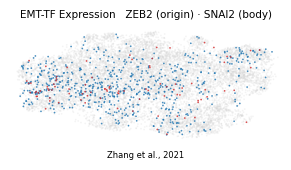

In [ ]:
xl = adata.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
def vec(g):
    x=adata[:,g].X; return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
thr={}
for g in [body_tf, terminus_tf]:
    v=vec(g); pos=v[v>0]; thr[g]=float(np.quantile(pos,0.75)) if pos.size else 0.0
sel={g: vec(g)>thr[g] for g in [body_tf, terminus_tf]}
order = sorted([body_tf,terminus_tf], key=lambda g:-int(sel[g].sum()))
colors={body_tf:'tab:blue', terminus_tf:'tab:red'}
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, size=6, alpha=.25, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    sc.pl.umap(adata[sel[g]].copy(), na_color=colors[g], size=6, alpha=.8, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title(f'EMT-TF Expression   {body_tf} (origin) \u00b7 {terminus_tf} (body)', size=7.5)
ax.text(.5,-.14, CITE, ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight'); plt.show()
for g in [body_tf,terminus_tf]:
    print(f'{g}: {(vec(g)>0).mean()*100:.1f}% expressing; {int(sel[g].sum())} shown; mean pseudotime of shown = {tn[sel[g]].mean():.2f}')
print('saved expression.pdf')